In [1]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

In [2]:
iris_dataset = load_iris()
print(iris_dataset["DESCR"])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [3]:
X, y = iris_dataset["data"], iris_dataset["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
print(f"Number of training samples: {X_train.shape}")
print(f"Number of test samples: {X_test.shape}")

Number of training samples: (112, 4)
Number of test samples: (38, 4)


In [4]:
def effect_num_neighbors(n_neighbors: int) -> None:
  knn = KNeighborsClassifier(n_neighbors=n_neighbors)
  knn.fit(X_train[:, 2:], y_train)
  color_dict = {0: "red", 1: "blue", 2: "green"}
  plt.scatter(X_train[:, 2], X_train[:, 3], c=[color_dict[i] for i in y_train])

  x,y = np.meshgrid(np.linspace(X_train[:, 2].min(), X_train[:, 2].max(), 300),
                    np.linspace(X_train[:, 3].min(), X_train[:, 3].max(), 300))
  z =  knn.predict(np.c_[x.ravel(), y.ravel()]).reshape(x.shape)

  plt.contourf(x, y, z, alpha = 0.25)
  plt.show()

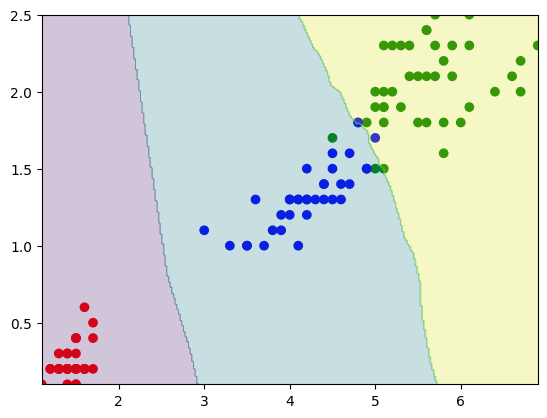

In [5]:
n_neighbors = 10

effect_num_neighbors(n_neighbors)

In [53]:
from scipy.spatial import distance_matrix
from numpy._core.multiarray import result_type
from typing import Literal
class MYKNN():
  def __init__(self, n_neighbors: int, norm: int = 2) -> None:
    self.n_neighbors = n_neighbors
    self.norm = norm
  def fit(self, X_train, y_train):
    self.X_train = X_train
    self.y_train = y_train
  def predict(self, X_test: np.ndarray, mode: Literal["classification", "regression"] = "classification") -> np.ndarray:
    distance_matrix = self._compute_distance(X_test, self.X_train)
    indices_of_k_nearest = np.argsort(distance_matrix, axis = 1)[:, :self.n_neighbors]
    k_nearest_neaghbor_values = self.y_train[indices_of_k_nearest]
    if mode == "classification":

      y_pred = np.apply_along_axis(
          lambda x: np.argmax(np.bincount(x)),
          axis = 1, arr=k_nearest_neaghbor_values
      )
      return y_pred
    else:
      y_pred = np.mean(k_nearest_neaghbor_values, axis = 1)
      result = np.zeros(len(X_test))
  def _compute_distance(self, X_test:np.ndarray, X_train: np.ndarray) -> np.ndarray:
    distance_matrix = np.linalg.norm(
        X_test[:, None, :] - X_train,
        ord = self.norm, axis=-1
    )
    return distance_matrix

In [54]:
iris_dataset = load_iris()
X, y = iris_dataset["data"], iris_dataset["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

kNN = MYKNN(n_neighbors=20, norm=2)
kNN.fit(X_train, y_train)

y_pred = kNN.predict(X_test)
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy={accuracy}")
print(y_pred == y_test)

Accuracy=0.9736842105263158
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True False]


In [ ]:
import numpy as np

dim = 10
data_size = 30
num_samples = 100

ratio_test